In [35]:
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.preprocessing import QuantileTransformer, RobustScaler, label_binarize
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC

BASE_DIR = Path.cwd().parent.parent

# Carregar divisões já preparadas no pipeline
X_train = pd.read_csv(BASE_DIR / "data/processed/X_train.csv")
X_test = pd.read_csv(BASE_DIR / "data/processed/X_test.csv")
y_train = pd.read_csv(BASE_DIR / "data/processed/y_train.csv").values.ravel()
y_test = pd.read_csv(BASE_DIR / "data/processed/y_test.csv").values.ravel()

In [36]:
# 1. Definição das colunas de exames bioquímicos confirmatórios a remover
biomarker_cols = ["FERRITTE", "B12", "FOLATE", "TSD"]

# 2. Remoção das variáveis em treino e teste (mantendo apenas hemograma e perfil clínico)
X_train_hemograma = X_train.drop(columns=biomarker_cols)
X_test_hemograma = X_test.drop(columns=biomarker_cols)

print(
    f"Dimensão original de features: {X_train.shape[1]} -> Nova dimensão: {X_train_hemograma.shape[1]}"
)
print("Features restantes:", list(X_train_hemograma.columns))

# 3. Novo escalonamento nos dados reduzidos (fit estritamente no treino)
scaler_hemograma = QuantileTransformer(
    output_distribution="normal", random_state=42
)
X_train_hem_scaled = scaler_hemograma.fit_transform(X_train_hemograma)
X_test_hem_scaled = scaler_hemograma.transform(X_test_hemograma)

Dimensão original de features: 24 -> Nova dimensão: 20
Features restantes: ['GENDER', 'WBC', 'NE#', 'LY#', 'MO#', 'EO#', 'BA#', 'RBC', 'HGB', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW', 'PLT', 'MPV', 'PCT', 'PDW', 'SD', 'SDTSD']


In [37]:
# 1. Instancia o estimador base
base_svc_hem = SVC(
    kernel="rbf",
    C=100.0,
    gamma=0.001,
    class_weight="balanced",
    random_state=42,
)

# 2. Calibração via Platt Scaling
calibrated_svm_hem = CalibratedClassifierCV(
    estimator=base_svc_hem, method="sigmoid", ensemble=False, cv=5
)

# 3. Treinamento
print("Treinando SVM apenas com features de hemograma...")
calibrated_svm_hem.fit(X_train_hem_scaled, y_train)
print("Treinamento concluído!")

Treinando SVM apenas com features de hemograma...
Treinamento concluído!


In [38]:
y_pred_hem = calibrated_svm_hem.predict(X_test_hem_scaled)

target_names = [
    "Sem Anemia (0)",
    "HGB (1)",
    "Ferro (2)",
    "Folato (3)",
    "B12 (4)",
]

print("Relatório de Classificação (Apenas Hemograma):")
print(
    classification_report(
        y_test, y_pred_hem, target_names=target_names, digits=4
    )
)

print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, y_pred_hem))

Relatório de Classificação (Apenas Hemograma):
                precision    recall  f1-score   support

Sem Anemia (0)     0.9961    0.9748    0.9854      2902
       HGB (1)     0.5467    0.6546    0.5958       304
     Ferro (2)     0.9433    0.9170    0.9300      1253
    Folato (3)     0.1593    0.3913    0.2264        46
       B12 (4)     0.1379    0.0678    0.0909        59

      accuracy                         0.9200      4564
     macro avg     0.5567    0.6011    0.5657      4564
  weighted avg     0.9322    0.9200    0.9250      4564


Matriz de Confusão:
[[2829   21   48    2    2]
 [   4  199   12   73   16]
 [   4   91 1149    4    5]
 [   2   21    3   18    2]
 [   1   32    6   16    4]]


In [28]:
# 1. Espaço de busca para os hiperparâmetros C e gamma
param_grid = {
    "C": [0.1, 1.0, 10.0, 100.0],
    "gamma": ["scale", "auto", 0.001, 0.01, 0.1],
}

# 2. Estratégia de validação cruzada estratificada (5 folds)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Estimador base para a busca
base_svc_grid = SVC(kernel="rbf", class_weight="balanced", random_state=42)

# 4. Grid Search focado em f1_macro (atenção equilibrada a todas as 5 classes)
grid_search = GridSearchCV(
    estimator=base_svc_grid,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=2,
    refit=False,  # O refit com calibração será feito explicitamente na próxima célula
)

print("Iniciando busca em grade para C e gamma...")
grid_search.fit(X_train_scaled, y_train)

print("\n--- Resultados do Grid Search ---")
print(f"Melhores parâmetros: {grid_search.best_params_}")
print(f"Melhor F1-Macro médio (CV): {grid_search.best_score_:.4f}")

Iniciando busca em grade para C e gamma...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

--- Resultados do Grid Search ---
Melhores parâmetros: {'C': 100.0, 'gamma': 0.001}
Melhor F1-Macro médio (CV): 0.8435


In [29]:
# 1. Recupera os melhores hiperparâmetros encontrados
best_params = grid_search.best_params_

# 2. Instancia o SVC com os parâmetros ótimos
optimized_base_svc = SVC(
    kernel="rbf", class_weight="balanced", random_state=42, **best_params
)

# 3. Encapsula no CalibratedClassifierCV com Platt scaling
calibrated_optimized_svm = CalibratedClassifierCV(
    estimator=optimized_base_svc, method="sigmoid", ensemble=False, cv=5
)

# 4. Treina o pipeline calibrado no conjunto de treino completo
print(f"Treinando modelo calibrado com os parâmetros: {best_params}...")
calibrated_optimized_svm.fit(X_train_scaled, y_train)
print("Treinamento e calibração concluídos com sucesso!")# 1. Predição no conjunto de teste escalonado
y_pred_opt = calibrated_optimized_svm.predict(X_test_scaled)

target_names = [
    "Sem Anemia (0)",
    "HGB (1)",
    "Ferro (2)",
    "Folato (3)",
    "B12 (4)",
]

print("Relatório de Classificação (SVM Otimizado e Calibrado):")
print(
    classification_report(
        y_test, y_pred_opt, target_names=target_names, digits=4
    )
)

print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, y_pred_opt))

Treinando modelo calibrado com os parâmetros: {'C': 100.0, 'gamma': 0.001}...
Treinamento e calibração concluídos com sucesso!
Relatório de Classificação (SVM Otimizado e Calibrado):
                precision    recall  f1-score   support

Sem Anemia (0)     0.9979    0.9676    0.9825      2902
       HGB (1)     0.7354    0.9507    0.8293       304
     Ferro (2)     0.9569    0.9210    0.9386      1253
    Folato (3)     0.5970    0.8696    0.7080        46
       B12 (4)     0.6310    0.8983    0.7413        59

      accuracy                         0.9518      4564
     macro avg     0.7836    0.9214    0.8399      4564
  weighted avg     0.9603    0.9518    0.9544      4564


Matriz de Confusão:
[[2808   34   44    8    8]
 [   3  289    6    3    3]
 [   3   66 1154   13   17]
 [   0    3    0   40    3]
 [   0    1    2    3   53]]


In [30]:
# Salva o estimador final otimizado e calibrado
models_dir = BASE_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "calibrated_svm_optimized.pkl"
joblib.dump(calibrated_optimized_svm, model_path)

print(f"Modelo salvo com sucesso em: {model_path}")

Modelo salvo com sucesso em: Z:\anemia_ml_project\models\calibrated_svm_optimized.pkl


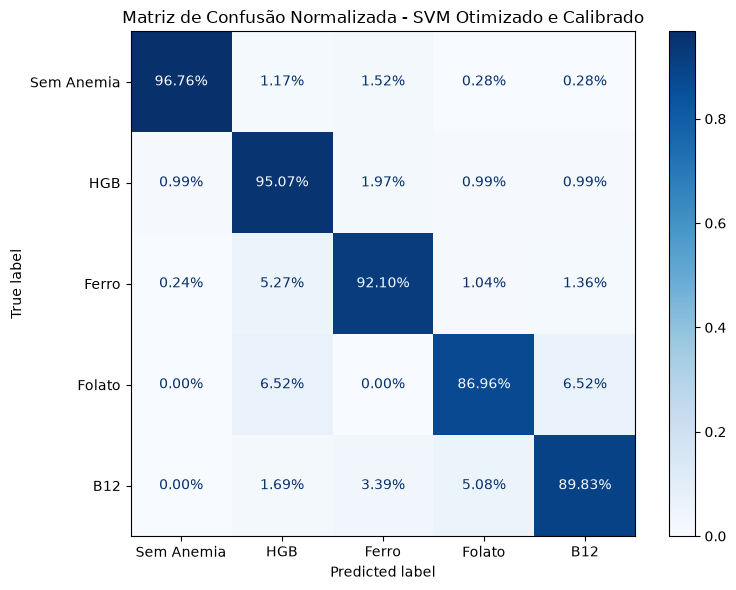

In [31]:
outputs_dir = BASE_DIR / "outputs"
outputs_dir.mkdir(parents=True, exist_ok=True)

class_names = ["Sem Anemia", "HGB", "Ferro", "Folato", "B12"]

# Matriz de Confusão Normalizada por linha (recall de cada patologia)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_opt,
    display_labels=class_names,
    cmap="Blues",
    normalize="true",
    values_format=".2%",
    ax=ax,
)

plt.title("Matriz de Confusão Normalizada - SVM Otimizado e Calibrado")
plt.tight_layout()
plt.savefig(
    outputs_dir / "svm_confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

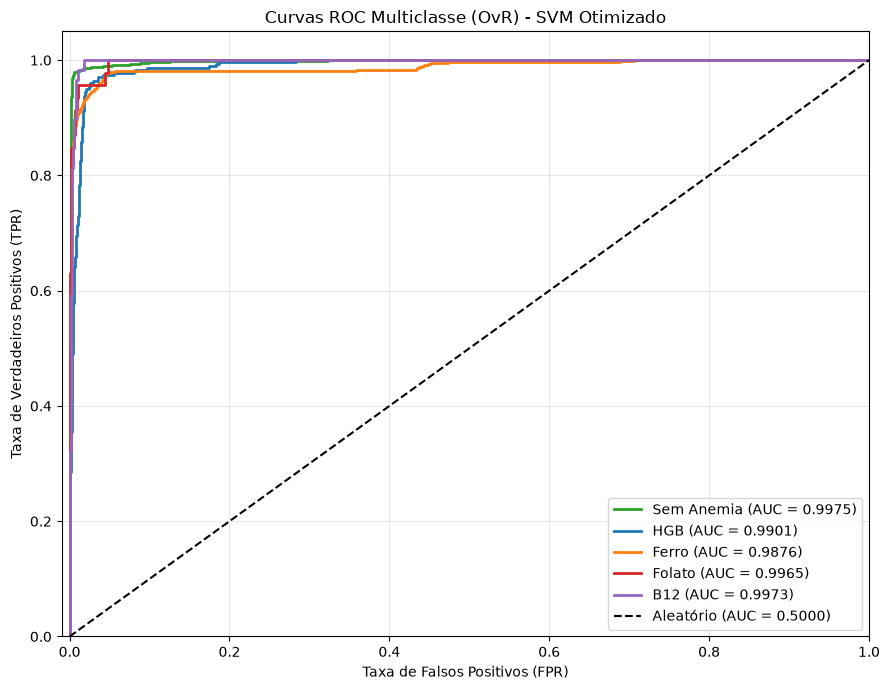

In [32]:
n_classes = len(class_names)

# Obtenção das probabilidades calibradas (Platt Scaling)
y_prob_opt = calibrated_optimized_svm.predict_proba(X_test_scaled)
y_test_bin = label_binarize(y_test, classes=range(n_classes))

# Curvas ROC One-vs-Rest (OvR)
fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728", "#9467bd"]

for i, color in enumerate(colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_opt[:, i])
    auc_score = roc_auc_score(y_test_bin[:, i], y_prob_opt[:, i])
    ax.plot(
        fpr,
        tpr,
        color=color,
        lw=2,
        label=f"{class_names[i]} (AUC = {auc_score:.4f})",
    )

ax.plot([0, 1], [0, 1], "k--", lw=1.5, label="Aleatório (AUC = 0.5000)")
ax.set_xlim([-0.01, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("Taxa de Falsos Positivos (FPR)")
ax.set_ylabel("Taxa de Verdadeiros Positivos (TPR)")
ax.set_title("Curvas ROC Multiclasse (OvR) - SVM Otimizado")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(outputs_dir / "svm_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [33]:
# Cálculo final das métricas globais de área sob a curva
auc_macro = roc_auc_score(
    y_test_bin, y_prob_opt, average="macro", multi_class="ovr"
)
auc_weighted = roc_auc_score(
    y_test_bin, y_prob_opt, average="weighted", multi_class="ovr"
)

print(f"ROC AUC Score (Macro OvR): {auc_macro:.4f}")
print(f"ROC AUC Score (Weighted OvR): {auc_weighted:.4f}")

ROC AUC Score (Macro OvR): 0.9938
ROC AUC Score (Weighted OvR): 0.9943
